# Heart Disease Risk Prediction

An end-to-end machine learning project that predicts whether a person is at risk of heart disease from symptoms, lifestyle risk factors and age.

**Objective:** build and compare classification models, then turn the best one into a simple tool that returns a risk prediction and probability for a new patient.

**Dataset:** 70,000 records with 18 features and a balanced binary target (`Heart_Risk`).

**Approach:** data inspection, exploratory analysis, cleaning, feature engineering, leakage-safe preprocessing, comparison of three models (KNN, Random Forest, SVM), and an interactive prediction step.

> For educational purposes only. This is not a medical diagnostic tool.

## 1. Import libraries

Import the libraries for data handling (pandas, NumPy), visualisation (Matplotlib, Seaborn) and modelling (scikit-learn).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 2. Load the dataset

Load `heart_disease.csv` into a pandas DataFrame, which is the starting point for all later analysis.

In [2]:
df = pd.read_csv('heart_disease.csv')

## 3. Inspect the data

Before any modelling, review the first and last rows, column names, data types, shape and summary statistics.

**Findings:** 70,000 rows and 19 columns, all numeric. Almost every feature is binary (0/1) and only `Age` is continuous.

In [3]:
df.head()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,48,0
1,0,1,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,46,0
2,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,66,0
3,1,1,0,1,0,0,1,1,1,0,1,1,0,1,1,1,1,60,1
4,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,69,0


In [4]:
df.tail()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
69995,0,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,30,0
69996,1,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,56,1
69997,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,1,53,0
69998,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,57,1
69999,1,1,1,1,1,1,1,0,1,0,1,0,1,0,0,1,0,51,1


In [5]:
print(df.columns)

Index(['Chest_Pain', 'Shortness_of_Breath', 'Fatigue', 'Palpitations',
       'Dizziness', 'Swelling', 'Pain_Arms_Jaw_Back', 'Cold_Sweats_Nausea',
       'High_BP', 'High_Cholesterol', 'Diabetes', 'Smoking', 'Obesity',
       'Sedentary_Lifestyle', 'Family_History', 'Chronic_Stress', 'Gender',
       'Age', 'Heart_Risk'],
      dtype='str')


In [6]:
print(df.dtypes)

Chest_Pain             int64
Shortness_of_Breath    int64
Fatigue                int64
Palpitations           int64
Dizziness              int64
Swelling               int64
Pain_Arms_Jaw_Back     int64
Cold_Sweats_Nausea     int64
High_BP                int64
High_Cholesterol       int64
Diabetes               int64
Smoking                int64
Obesity                int64
Sedentary_Lifestyle    int64
Family_History         int64
Chronic_Stress         int64
Gender                 int64
Age                    int64
Heart_Risk             int64
dtype: object


In [7]:
print(df.shape)

(70000, 19)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Chest_Pain           70000 non-null  int64
 1   Shortness_of_Breath  70000 non-null  int64
 2   Fatigue              70000 non-null  int64
 3   Palpitations         70000 non-null  int64
 4   Dizziness            70000 non-null  int64
 5   Swelling             70000 non-null  int64
 6   Pain_Arms_Jaw_Back   70000 non-null  int64
 7   Cold_Sweats_Nausea   70000 non-null  int64
 8   High_BP              70000 non-null  int64
 9   High_Cholesterol     70000 non-null  int64
 10  Diabetes             70000 non-null  int64
 11  Smoking              70000 non-null  int64
 12  Obesity              70000 non-null  int64
 13  Sedentary_Lifestyle  70000 non-null  int64
 14  Family_History       70000 non-null  int64
 15  Chronic_Stress       70000 non-null  int64
 16  Gender               70000 non-nu

In [9]:
df.describe()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,0.499229,0.500586,0.498571,0.498729,0.501414,0.498929,0.501500,0.502457,0.497429,0.499214,0.500643,0.502971,0.499157,0.503543,0.497629,0.499957,0.548929,54.461986,0.500000
std,0.500003,0.500003,0.500002,0.500002,0.500002,0.500002,0.500001,0.499998,0.499997,0.500003,0.500003,0.499995,0.500003,0.499991,0.499998,0.500004,0.497604,16.410794,0.500004
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45.000000,0.000000
50%,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,56.000000,0.500000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,67.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,84.000000,1.000000


## 4. Check missing values

Count null values per column. Missing data can bias a model or cause training to fail, so this is checked first.

In [10]:
df.isnull().sum()

Chest_Pain             0
Shortness_of_Breath    0
Fatigue                0
Palpitations           0
Dizziness              0
Swelling               0
Pain_Arms_Jaw_Back     0
Cold_Sweats_Nausea     0
High_BP                0
High_Cholesterol       0
Diabetes               0
Smoking                0
Obesity                0
Sedentary_Lifestyle    0
Family_History         0
Chronic_Stress         0
Gender                 0
Age                    0
Heart_Risk             0
dtype: int64

## 5. Data distribution

Plot the age distribution and a histogram for every column to understand how values are spread and whether the classes are balanced.

**Findings:** the target classes are roughly 50/50, so accuracy is a fair metric and no resampling is needed.

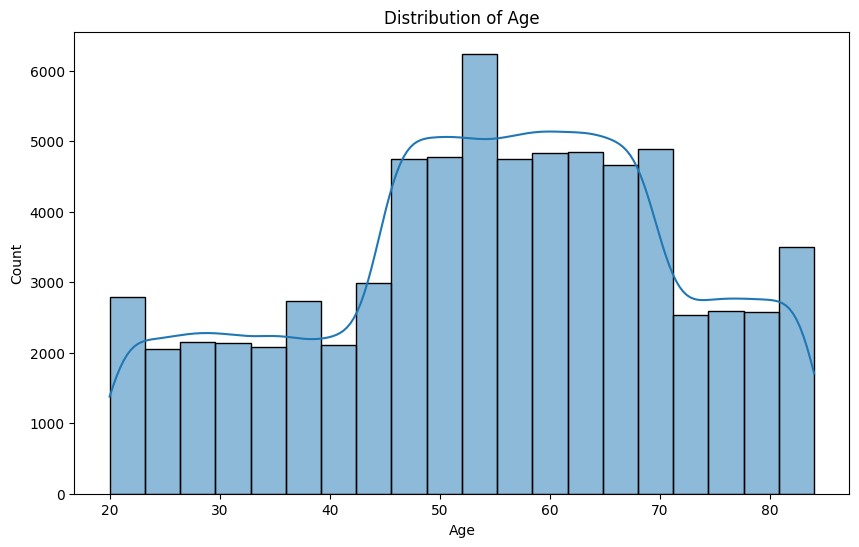

In [11]:
plt.figure(figsize=(10,6))

sns.histplot(df["Age"], bins=20, kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

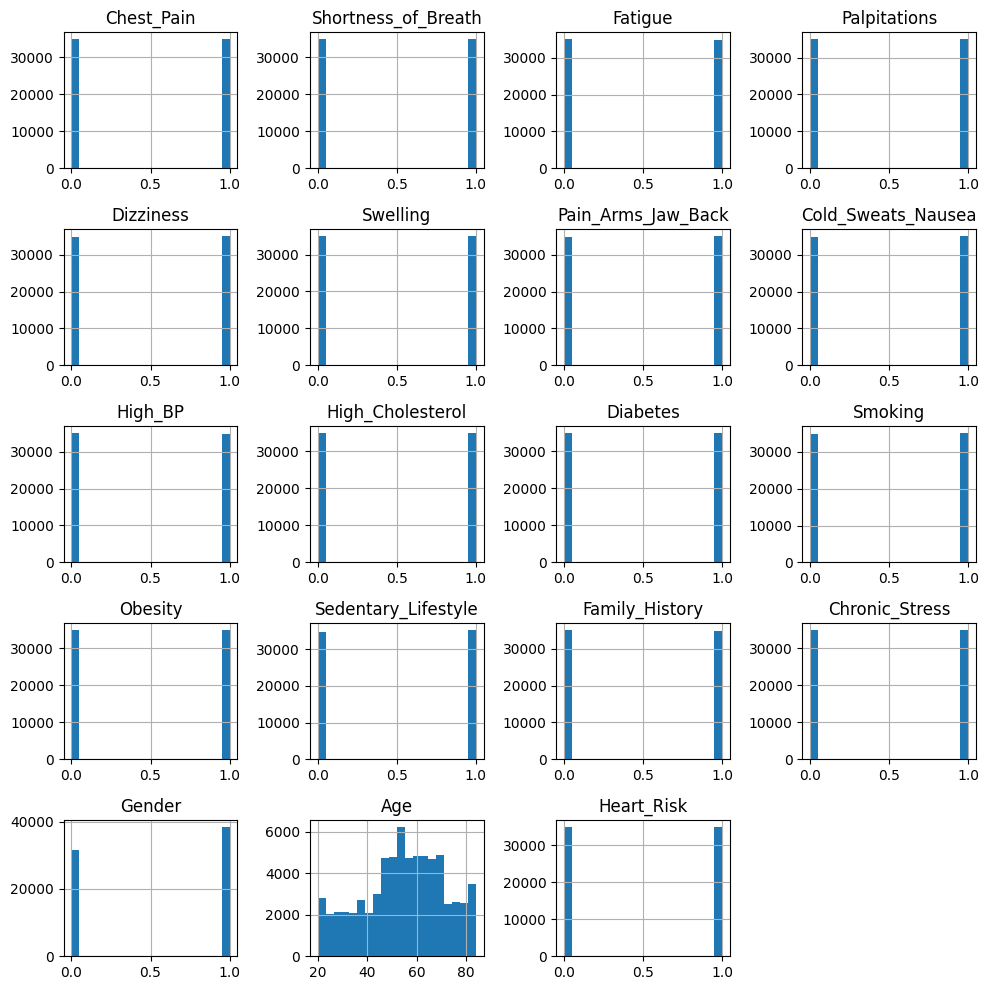

In [12]:
df.hist(figsize=(10, 10), bins=20)

plt.tight_layout()
plt.show()

## 6. Handle missing values

Apply `dropna()` as a safeguard. The shape stays at (70000, 19), which confirms the dataset has no missing values and nothing was lost.

In [13]:
print("Original shape: ",df.shape)
df_drop=df.dropna()

print("shape after removing missing values:", df_drop.shape)
print("\n Missing values after dropna():")
print(df_drop.isnull().sum())

Original shape:  (70000, 19)
shape after removing missing values: (70000, 19)

 Missing values after dropna():
Chest_Pain             0
Shortness_of_Breath    0
Fatigue                0
Palpitations           0
Dizziness              0
Swelling               0
Pain_Arms_Jaw_Back     0
Cold_Sweats_Nausea     0
High_BP                0
High_Cholesterol       0
Diabetes               0
Smoking                0
Obesity                0
Sedentary_Lifestyle    0
Family_History         0
Chronic_Stress         0
Gender                 0
Age                    0
Heart_Risk             0
dtype: int64


## 7. Correlation heatmap

Visualise the correlation between all features and the target to see which variables carry the most signal.

**Findings:** `Age` and the symptom features (chest pain, arm/jaw/back pain, cold sweats, dizziness) show the strongest relationship with `Heart_Risk`. Chronic risk factors such as high blood pressure and cholesterol show moderate correlation.

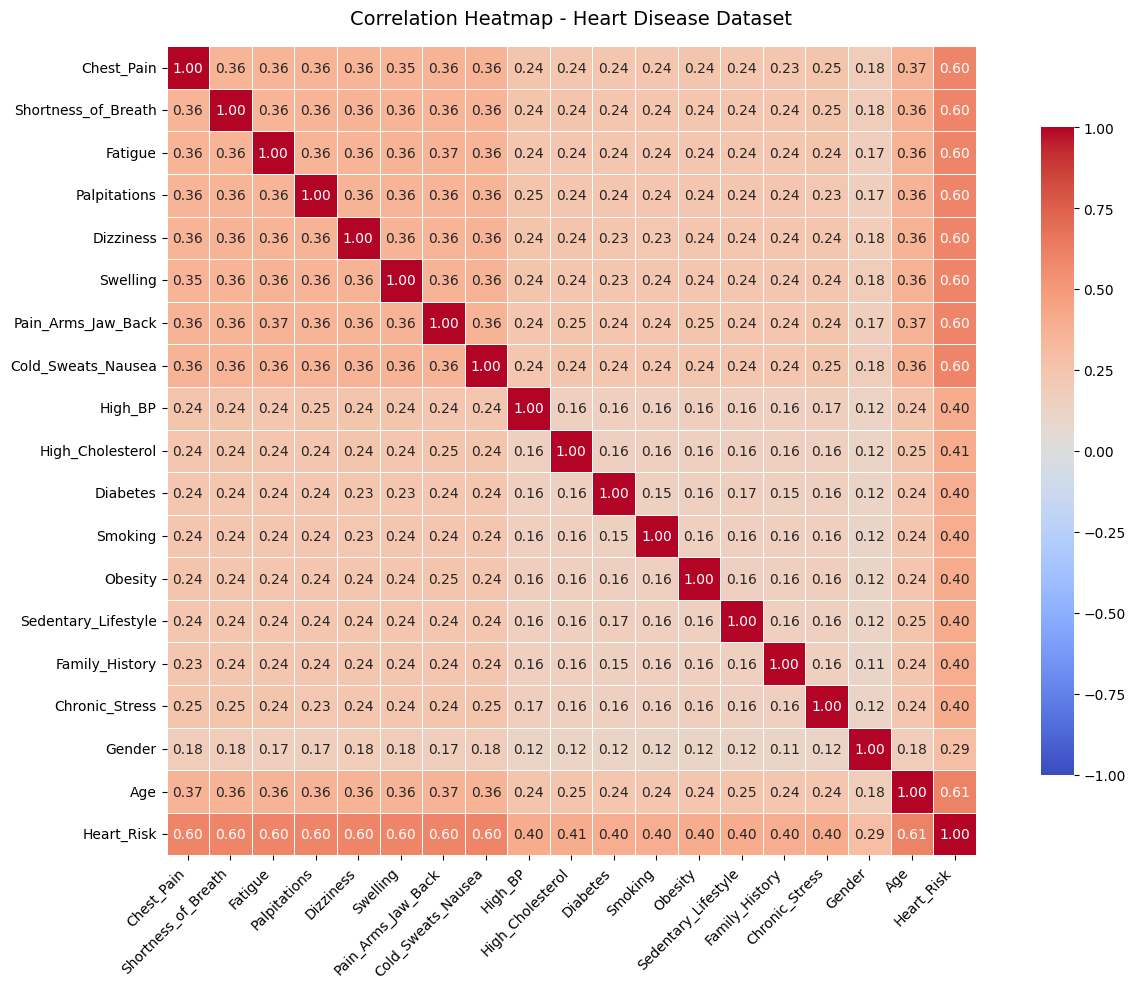

In [14]:

corr=df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap - Heart Disease Dataset", fontsize=14, pad=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

## 8. Outlier detection (IQR method)

Detect outliers in `Age` using the interquartile range, flagging values outside Q1 − 1.5×IQR and Q3 + 1.5×IQR. Only `Age` is checked because the other columns are binary.

**Findings:** the valid range is 12 to 100 and no outliers were found, so no records needed to be removed or capped.

In [15]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Age is the only continuous column here; the rest are binary 0/1
outliers, low, high = detect_outliers_iqr(df, "Age")
print(f"Valid Age range: {low:.1f} to {high:.1f}")
print(f"Number of outliers found: {len(outliers)}")

Valid Age range: 12.0 to 100.0
Number of outliers found: 0


## 9. Inconsistent entries and duplicates

Check data integrity in two ways: remove exact duplicate rows, and confirm every binary column contains only 0 or 1.

**Findings:** 6,245 duplicate rows were removed (70,000 → 63,755). No invalid values were found. Removing duplicates before the train-test split prevents identical records from appearing in both sets, which would inflate test accuracy.

In [16]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Check all binary columns only contain 0/1 (catches typos like 0.5, 2, -1, etc.)
binary_cols = df.columns.drop(["Age", "Heart_Risk"])
for col in binary_cols:
    bad_values = df[~df[col].isin([0, 1])]
    if len(bad_values) > 0:
        print(f"Inconsistent values in {col}:", bad_values[col].unique())

print("Shape after cleanup:", df.shape)

Duplicate rows: 6245
Shape after cleanup: (63755, 19)


## 10. Recheck missing values

Confirm the cleaned dataset is still free of null values after the cleaning steps.

In [17]:
print(df.isnull().sum())


Chest_Pain             0
Shortness_of_Breath    0
Fatigue                0
Palpitations           0
Dizziness              0
Swelling               0
Pain_Arms_Jaw_Back     0
Cold_Sweats_Nausea     0
High_BP                0
High_Cholesterol       0
Diabetes               0
Smoking                0
Obesity                0
Sedentary_Lifestyle    0
Family_History         0
Chronic_Stress         0
Gender                 0
Age                    0
Heart_Risk             0
dtype: int64


## 11. Feature engineering

Create additional features that capture clinical meaning:
- `Symptom_Count`: total number of symptoms a patient reports
- `Risk_Factor_Count`: total number of risk factors present
- `Age_Group`: age bands (<40, 40–55, 55–70, 70+), one-hot encoded

In [18]:

df["Symptom_Count"] = df[["Chest_Pain", "Shortness_of_Breath", "Fatigue",
                           "Palpitations", "Dizziness", "Swelling",
                           "Pain_Arms_Jaw_Back", "Cold_Sweats_Nausea"]].sum(axis=1)

df["Risk_Factor_Count"] = df[["High_BP", "High_Cholesterol", "Diabetes",
                               "Smoking", "Obesity", "Sedentary_Lifestyle",
                               "Family_History", "Chronic_Stress"]].sum(axis=1)

df["Age_Group"] = pd.cut(df["Age"], bins=[0, 40, 55, 70, 100],
                          labels=["<40", "40-55", "55-70", "70+"])
df = pd.get_dummies(df, columns=["Age_Group"], drop_first=True)

## 12. Feature selection

Select 8 input features: `Age`, `Chest_Pain`, `Shortness_of_Breath`, `High_BP`, `High_Cholesterol`, `Diabetes`, `Smoking`, `Family_History`.

These are the most practical details for a person to enter, and they match the input form used for prediction at the end. Using the same features for training and prediction keeps the model consistent with how it would be used.

In [19]:
# Use the same eight inputs as the simplified prediction form.
selected_features = [
    "Age", "Chest_Pain", "Shortness_of_Breath", "High_BP",
    "High_Cholesterol", "Diabetes", "Smoking", "Family_History",
]
X = df[selected_features]
y = df["Heart_Risk"]

## 13. Train-test split

Split the data 80% training / 20% testing (12,751 test samples). The split is **stratified**, so both sets keep the same class balance, and `random_state=42` makes results reproducible.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 14. Model training and comparison

Train three different algorithms on the same split and evaluate each with accuracy, a confusion matrix, and precision, recall and F1 for both classes. Using the same data for all three gives a fair comparison.

### Model 1: K-Nearest Neighbors

Distance-based model, with k = 5 and distance weighting. Because it depends on distances, features are standardised inside a scikit-learn `Pipeline`, so the scaler is fitted on training data only and no information leaks from the test set.

**Result:** 93.95% test accuracy.

In [21]:
# Scale inside the pipeline so the scaler is fitted only on the training data.
model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(
    y_test, y_pred, target_names=["No Heart Risk", "Heart Risk"], zero_division=0
))

Train accuracy: 0.9535722688416595
Test accuracy: 0.9394557289624343

Confusion matrix:
 [[6108  346]
 [ 426 5871]]

Classification report:
                precision    recall  f1-score   support

No Heart Risk       0.93      0.95      0.94      6454
   Heart Risk       0.94      0.93      0.94      6297

     accuracy                           0.94     12751
    macro avg       0.94      0.94      0.94     12751
 weighted avg       0.94      0.94      0.94     12751



### Model 2: Random Forest

An ensemble of 100 decision trees that captures non-linear patterns and is robust to overfitting. It is scale-invariant, so no scaling is needed.

**Result:** 94.02% test accuracy.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification report:\n", classification_report(
    y_test,
    y_pred,
    target_names=["No Heart Risk", "Heart Risk"],
    zero_division=0
))

Train accuracy: 0.9542388832248451
Test accuracy: 0.9401615559563956

Confusion matrix:
 [[6080  374]
 [ 389 5908]]

Classification report:
                precision    recall  f1-score   support

No Heart Risk       0.94      0.94      0.94      6454
   Heart Risk       0.94      0.94      0.94      6297

     accuracy                           0.94     12751
    macro avg       0.94      0.94      0.94     12751
 weighted avg       0.94      0.94      0.94     12751



### Model 3: Support Vector Machine (RBF kernel)

Finds a non-linear decision boundary between the classes, with standardisation applied inside the pipeline.

**Result:** 94.17% test accuracy, the best of the three. It also has the smallest gap between training (94.07%) and test accuracy, which indicates good generalisation and little overfitting.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Train accuracy:", model.score(X_train, y_train))
print("Test accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification report:\n", classification_report(
    y_test,
    y_pred,
    target_names=["No Heart Risk", "Heart Risk"],
    zero_division=0
))

Train accuracy: 0.9407105325072543
Test accuracy: 0.9416516351658694

Confusion matrix:
 [[6094  360]
 [ 384 5913]]

Classification report:
                precision    recall  f1-score   support

No Heart Risk       0.94      0.94      0.94      6454
   Heart Risk       0.94      0.94      0.94      6297

     accuracy                           0.94     12751
    macro avg       0.94      0.94      0.94     12751
 weighted avg       0.94      0.94      0.94     12751



## 15. New patient prediction

Train the final SVM (with probability estimates enabled) and enter a patient's details in an interactive form. The output is the predicted class (risk / no risk) and the associated probability, which shows how the model could be used on new data.

In [24]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Load dataset
if "df" not in globals():
    df = pd.read_csv("heart_disease.csv")

# Selected features
selected_features = [
    "Age", "Chest_Pain", "Shortness_of_Breath", "High_BP",
    "High_Cholesterol", "Diabetes", "Smoking", "Family_History"
]

# Prepare data
X = df[selected_features]
y = df["Heart_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# IMPORTANT: Always create and train a fresh SVM model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("SVM model trained successfully!")
print("Probability enabled:", model.named_steps["svm"].probability)


# Input function
def read_integer(prompt, minimum, maximum):
    while True:
        try:
            value = int(input(prompt))
            if minimum <= value <= maximum:
                return value
        except ValueError:
            pass

        print(f"Enter a number between {minimum} and {maximum}.")


# Input labels
input_labels = {
    "Age": "Age in years",
    "Chest_Pain": "Chest pain",
    "Shortness_of_Breath": "Shortness of breath",
    "High_BP": "High blood pressure",
    "High_Cholesterol": "High cholesterol",
    "Diabetes": "Diabetes",
    "Smoking": "Smoking",
    "Family_History": "Family history of heart disease"
}

# Collect patient information
print("\nEnter patient information")
print("For Yes = 1 and No = 0")

patient_values = {}

for feature in selected_features:

    if feature == "Age":
        patient_values[feature] = read_integer(
            "Age (1-120): ", 1, 120
        )
    else:
        patient_values[feature] = read_integer(
            input_labels[feature] + " (1=Yes, 0=No): ",
            0, 1
        )


# Create new patient DataFrame
new_patient = pd.DataFrame(
    [patient_values],
    columns=selected_features
)

# Prediction
prediction = model.predict(new_patient)

# Probability prediction
probability = model.predict_proba(new_patient)

positive_class_index = list(model.classes_).index(1)

heart_risk_probability = probability[0][positive_class_index]

# Display result
print("\n========== HEART RISK PREDICTION ==========")

print("Predicted Heart Risk:", prediction[0])

print(
    "Heart Risk Probability:",
    f"{heart_risk_probability:.2%}"
)

if prediction[0] == 1:
    print("Result: Heart Risk Detected")
else:
    print("Result: No Heart Risk Detected")

print("===========================================")

c:\Users\king\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM model trained successfully!
Probability enabled: True

Enter patient information
For Yes = 1 and No = 0

========== HEART RISK PREDICTION ==========
Predicted Heart Risk: 1
Heart Risk Probability: 92.08%
Result: Heart Risk Detected


## 16. Conclusion

**Summary of results**

| Model | Train Accuracy | Test Accuracy |
|---|---|---|
| KNN | 95.36% | 93.95% |
| Random Forest | 95.42% | 94.02% |
| **SVM (RBF)** | 94.07% | **94.17%** |

- All three models reach about 94% accuracy with balanced precision and recall (0.94) for both classes, so the model is not biased toward one outcome.
- SVM was chosen for the final prediction tool because of its highest test accuracy and best generalisation.
- The data was cleaned (duplicates removed, integrity and outliers checked), and scaling was done inside a pipeline to avoid data leakage.

**Limitations**
- The dataset appears to be clean and possibly synthetic, so performance on real clinical data may differ.
- Only 8 features are used, and no clinical measurements (e.g. ECG, actual blood pressure values) are included.

**Future work**
- Hyperparameter tuning and cross-validation
- Gradient boosting models (XGBoost, LightGBM)
- Explainability with SHAP
- Deployment as a web app (e.g. Streamlit)
- Validation on a real-world clinical dataset